In [1]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path

# Find the CSV files in your project
def find_csv(filename):
    matches = list(Path.cwd().rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Cannot find {filename}. Download it and "
            "place it in your project folder."
        )
    return matches[0]

# Load both CSV files
orders = pd.read_csv(find_csv("store_orders.csv"))
customers = pd.read_csv(find_csv("store_customers.csv"))

# Create SQLite database
con = sqlite3.connect("store.db")

# Create database tables
orders.to_sql("orders", con, if_exists="replace", index=False)
customers.to_sql("customers", con, if_exists="replace", index=False)

# Verify tables
tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table'",
    con
)

print("Database Tables:")
print(tables)
print("Orders loaded:", len(orders))
print("Customers loaded:", len(customers))


Database Tables:
        name
0     orders
1  customers
Orders loaded: 200
Customers loaded: 40


In [2]:

query = """
SELECT *
FROM orders
LIMIT 5;
"""

first_five = pd.read_sql(query, con)

print("First 5 Orders:")
print(first_five)


First 5 Orders:
   order_id  customer_id  product     category  amount  order_date
0      5000            4    paper       office   14.09  2026-05-25
1      5001           15  planner       office   51.86  2026-05-08
2      5002           34    shelf    furniture  116.25  2026-06-03
3      5003            2  granola       snacks   19.72  2026-05-19
4      5004           17  monitor  electronics  284.80  2026-05-10


In [3]:

query = """
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC;
"""

high_orders = pd.read_sql(query, con)

print("Orders Over $100:")
print(high_orders)


Orders Over $100:
    order_id  customer_id  product     category  amount  order_date
0       5153           20     dock  electronics  499.00  2026-05-25
1       5140           30  headset  electronics  295.36  2026-05-26
2       5047          901  headset  electronics  293.79  2026-05-15
3       5150          903  monitor  electronics  293.35  2026-06-06
4       5014            6  monitor  electronics  287.83  2026-05-22
..       ...          ...      ...          ...     ...         ...
79      5107           38    shelf    furniture  110.31  2026-05-17
80      5046           13    shelf    furniture  108.47  2026-05-28
81      5009           14    chair    furniture  107.20  2026-05-24
82      5007           36     dock  electronics  103.77  2026-05-21
83      5023            9     desk    furniture  100.27  2026-06-05

[84 rows x 6 columns]


In [4]:

query = """
SELECT
    category,
    COUNT(*) AS n,
    ROUND(AVG(amount), 2) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC;
"""

category_summary = pd.read_sql(query, con)

print("Average Order Amount by Category:")
print(category_summary)


Average Order Amount by Category:
      category   n  avg_amount
0  electronics  60      190.57
1    furniture  46      146.25
2       office  51       30.13
3       snacks  43       14.62


In [4]:
# Category Analysis

# I used SQL to calculate the number of orders and the average amount spent in each product category. The results are organized from the highest to the lowest average order amount.

In [5]:

query = """
SELECT
    c.city,
    ROUND(SUM(o.amount), 2) AS total_spend
FROM orders AS o
INNER JOIN customers AS c
    ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC;
"""

city_spending = pd.read_sql(query, con)

print("Total Spending by City:")
print(city_spending)


Total Spending by City:
           city  total_spend
0   Los Angeles      5862.99
1   Culver City      5316.88
2  Santa Monica      4017.93
3     Inglewood      2718.25
4      Torrance      1037.25
5        Venice       462.36


In [6]:

total_orders = pd.read_sql(
    "SELECT COUNT(*) AS total FROM orders",
    con
).iloc[0]["total"]

joined_orders = pd.read_sql("""
SELECT COUNT(*) AS total
FROM orders AS o
INNER JOIN customers AS c
    ON o.customer_id = c.customer_id;
""", con).iloc[0]["total"]

missing_orders = total_orders - joined_orders

print("Total Orders:", total_orders)
print("Orders After JOIN:", joined_orders)
print("Unmatched Orders:", missing_orders)


Total Orders: 200
Orders After JOIN: 195
Unmatched Orders: 5


In [ ]:
# Row Count

# The original orders table contains 200 records, but the INNER JOIN returns only 195 records. This happens because five orders contain customer IDs that do not exist in the customers table.

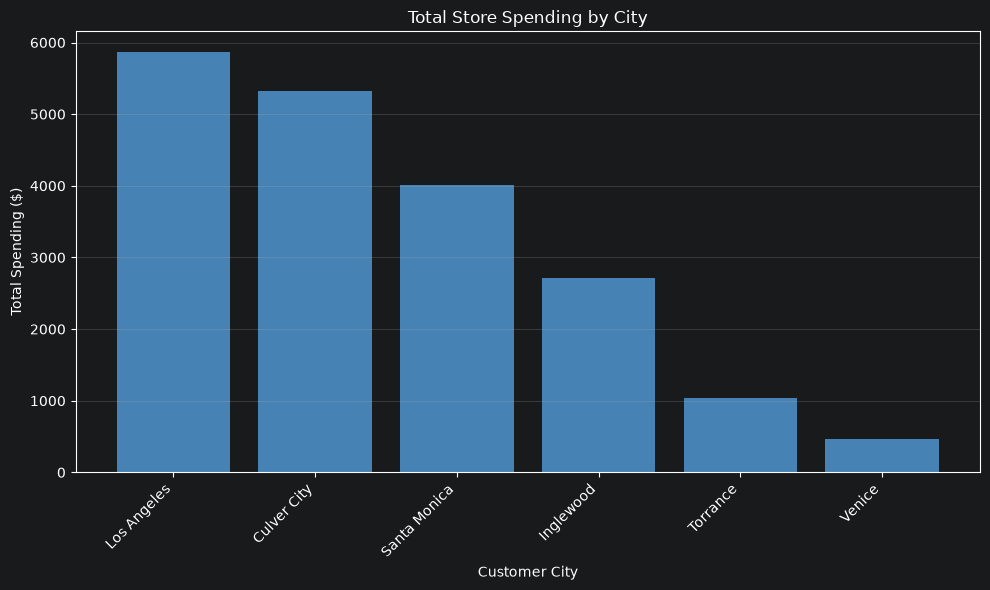

In [7]:

plt.figure(figsize=(10, 6))

plt.bar(
    city_spending["city"],
    city_spending["total_spend"],
    color="steelblue"
)

plt.title("Total Store Spending by City")
plt.xlabel("Customer City")
plt.ylabel("Total Spending ($)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:

query = """
SELECT
    product,
    COUNT(*) AS total_orders,
    ROUND(SUM(amount), 2) AS total_revenue
FROM orders
GROUP BY product
ORDER BY total_revenue DESC
LIMIT 5;
"""

top_products = pd.read_sql(query, con)

print("Top 5 Products by Revenue:")
print(top_products)

# Display the highest-revenue product
top_product = top_products.iloc[0]

print(
    f"\nThe highest-revenue product is "
    f"{top_product['product']} with "
    f"${top_product['total_revenue']:.2f} in sales."
)


Top 5 Products by Revenue:
   product  total_orders  total_revenue
0  headset            23        4902.30
1     dock            20        3357.14
2  monitor            17        3174.73
3    shelf            19        3030.45
4    chair            17        2589.93

The highest-revenue product is headset with $4902.30 in sales.


In [ ]:
# I used SQL to group orders by product, calculate total revenue, and sort the results from highest to lowest.

In [9]:
con.close()
print("Database connection closed successfully.")


Database connection closed successfully.
